# 03 · Churn prediction (LightGBM vs logistic-regression baseline)
Final results (25-iteration search) are in `reports/churn_model_metrics.json`; this notebook re-runs a shorter search (`n_iter=8`, not saved) to demonstrate the workflow.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Image
from src import config
pd.set_option('display.width', 160); sns.set_theme(style='whitegrid')
import json
from src import churn_model as cm
df = pd.read_csv(config.DATA_PROCESSED / 'customers_processed.csv')   # cleaned + engineered (written by ingestion)
res = cm.train_and_evaluate(df, n_iter=8, save=False); obj = res.pop('_objects')
for k in ['baseline_logreg','lightgbm']:
    print(k); print(pd.DataFrame({'cv_mean': res[k]['cv_mean'], 'cv_std': res[k]['cv_std']}).round(3))
print('best params', res['best_params'], '| calibration:', res['calibration_used'])

baseline_logreg
           cv_mean  cv_std
roc_auc      0.858   0.015
pr_auc       0.678   0.035
f1           0.616   0.020
recall       0.568   0.023
precision    0.673   0.024
accuracy     0.812   0.010
lightgbm
           cv_mean  cv_std
roc_auc      0.862   0.015
pr_auc       0.682   0.035
f1           0.616   0.016
recall       0.571   0.018
precision    0.669   0.024
accuracy     0.811   0.009
best params {'subsample_freq': 1, 'subsample': 0.85, 'reg_lambda': 1.0, 'reg_alpha': 1.0, 'num_leaves': 4, 'n_estimators': 150, 'min_child_samples': 20, 'max_depth': 3, 'learning_rate': 0.08, 'colsample_bytree': 0.9, 'class_weight': None} | calibration: sigmoid


In [2]:
rows = {n: {m: v for m, v in res[k][s].items() if m != 'confusion_matrix'} for n, k, s in [('LogReg @0.5','baseline_logreg','test_at_0.5'),('LightGBM @0.5','lightgbm','test_at_0.5'),('LightGBM @tuned thr','lightgbm','test_at_tuned_threshold')]}
display(pd.DataFrame(rows).T.round(3))
print(res['lightgbm']['test_at_0.5']['confusion_matrix'])

,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,brier
LogReg @0.5,0.500,0.798,0.641,0.540,0.586,0.850,0.670,0.134
LightGBM @0.5,0.500,0.798,0.637,0.553,0.592,0.856,0.681,0.132
LightGBM @tuned thr,0.377,0.795,0.597,0.698,0.644,0.856,0.681,0.132


{'tn': 917, 'fp': 118, 'fn': 167, 'tp': 207}


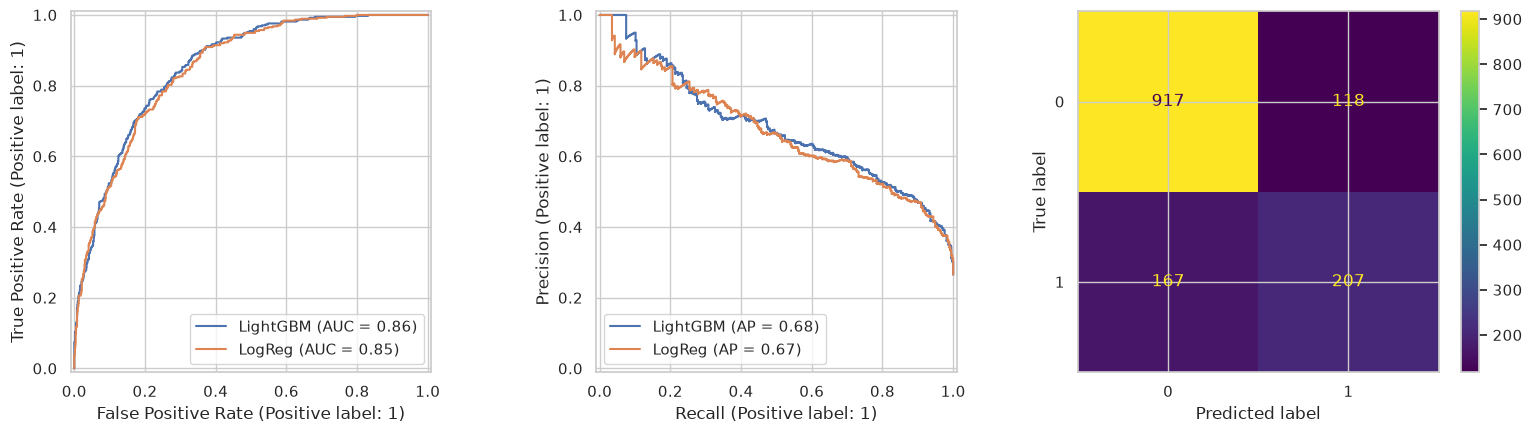

In [3]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5)); y, p, b = obj['y_test'], obj['proba_test'], obj['base_proba_test']
RocCurveDisplay.from_predictions(y, p, name='LightGBM', ax=ax[0]); RocCurveDisplay.from_predictions(y, b, name='LogReg', ax=ax[0])
PrecisionRecallDisplay.from_predictions(y, p, name='LightGBM', ax=ax[1]); PrecisionRecallDisplay.from_predictions(y, b, name='LogReg', ax=ax[1])
ConfusionMatrixDisplay.from_predictions(y, (p >= 0.5).astype(int), ax=ax[2]); plt.tight_layout()

Text(0.5, 1.0, 'Calibration (hold-out)')

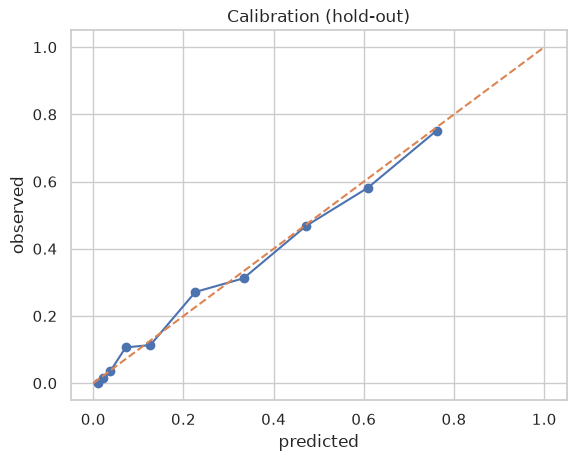

In [4]:
c = res['calibration_curve']; plt.plot(c['prob_pred'], c['prob_true'], 'o-'); plt.plot([0,1],[0,1],'--'); plt.xlabel('predicted'); plt.ylabel('observed'); plt.title('Calibration (hold-out)')

## Saved final model (25-iteration search)

In [5]:
final = json.load(open(config.REPORTS_DIR / 'churn_model_metrics.json'))
print({k: round(v,3) for k, v in final['lightgbm']['test_at_0.5'].items() if k != 'confusion_matrix'})

{'threshold': 0.5, 'accuracy': 0.803, 'precision': 0.641, 'recall': 0.583, 'f1': 0.611, 'roc_auc': 0.857, 'pr_auc': 0.684, 'brier': 0.132}


## SHAP explanations
SHAP values describe what the model associates with churn; they are not causal.

,feature,mean_abs_shap
0,contract_months,0.883
1,dependents,0.570
2,tenure_months,0.425
3,internet_service_Fiber optic,0.220
4,electronic_check,0.163
5,has_internet,0.156
6,paperless_billing,0.091
7,monthly_charges,0.075
8,streaming_movies,0.070
9,streaming_tv,0.065


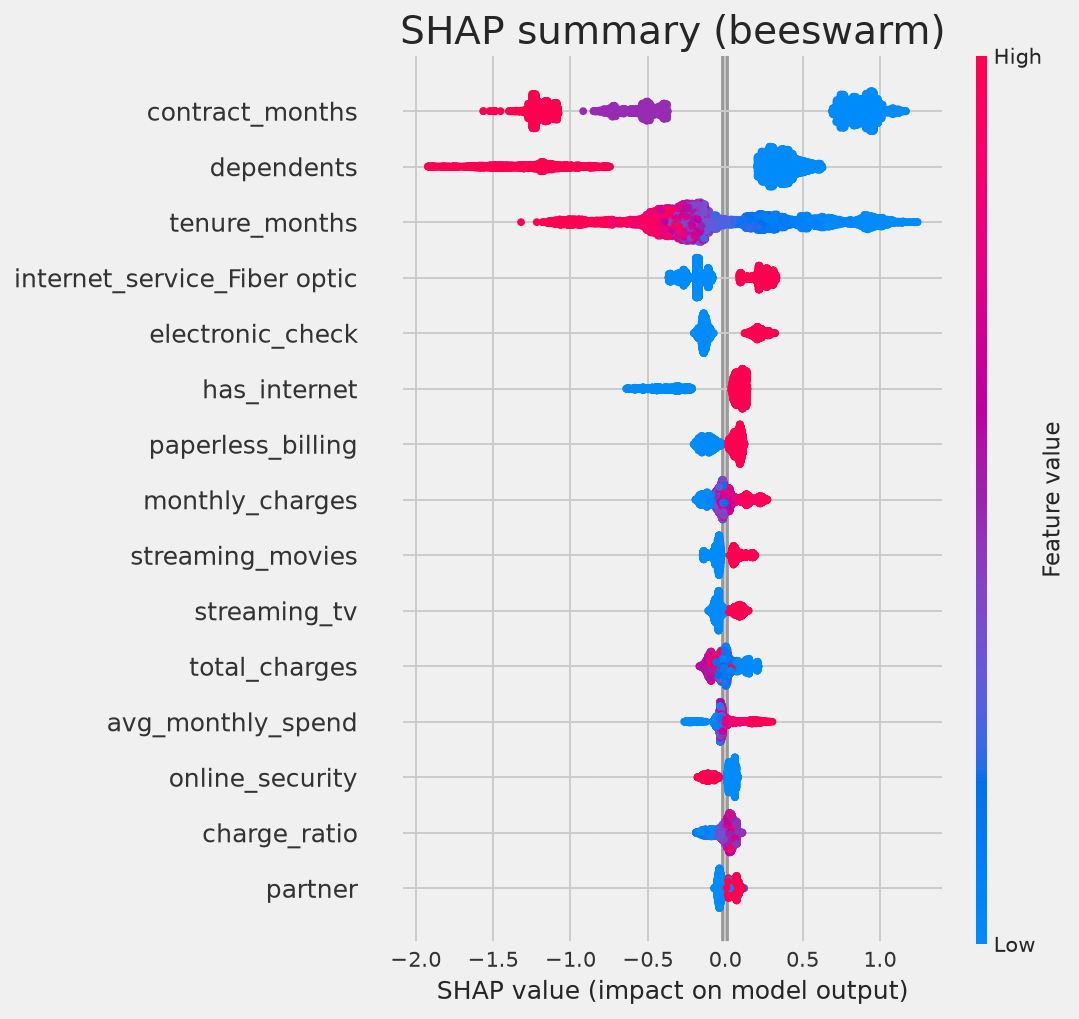

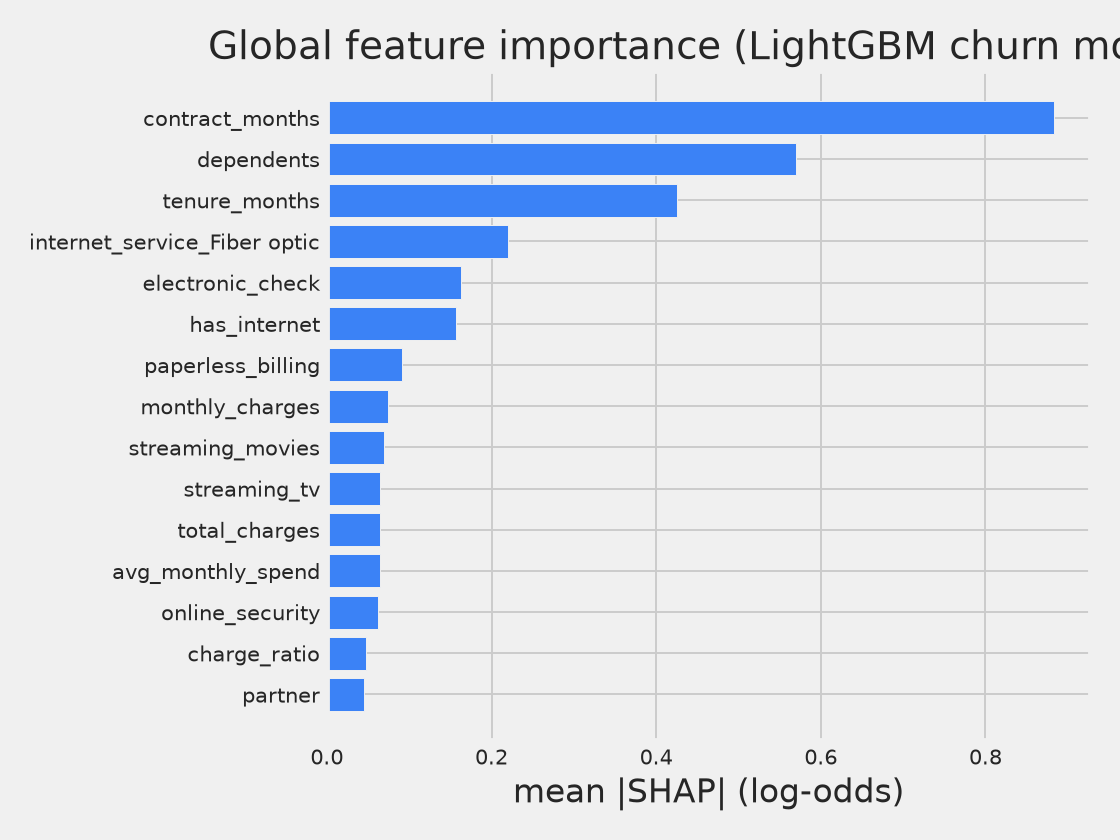

In [6]:
from src import shap_analysis as sa
import joblib
pipe = joblib.load(config.MODELS_DIR / 'churn_lgbm_explainer.joblib')
sdf, Xt, base = sa.compute_shap(pipe, df)
display(sa.global_importance(sdf).head(12).round(3))
for f in ['shap_summary','shap_global_importance']: display(Image(str(config.FIGURES_DIR / (f + '.png'))))

In [7]:
i = int(np.argmax(df.churn.values)); print(df.customer_id[i]); display(sa.top_factors(sdf.iloc[i], Xt.iloc[i]).round(3))

0004-TLHLJ


,feature,value,shap_log_odds,direction
0,contract_months,1.0,0.970,raises churn risk
1,tenure_months,4.0,0.513,raises churn risk
2,dependents,0.0,0.277,raises churn risk
3,internet_service_Fiber optic,1.0,0.248,raises churn risk
4,electronic_check,1.0,0.198,raises churn risk
5,has_internet,1.0,0.133,raises churn risk
6,paperless_billing,1.0,0.103,raises churn risk
7,online_security,0.0,0.068,raises churn risk
